# Heart Disease Risk Prediction with Machine Learning

**Prevention of cardiovascular diseases** — INSEEC  Big Data & AI, individual project by Ketsia Kemougne.

**Research question:** to what extent can supervised machine learning models, applied to a standardised clinical dataset of 270 patients, predict the presence of heart disease more accurately than single-variable risk assessment?

**Pipeline**
1. Setup and data loading
2. Exploratory data analysis (distributions, correlations, scatterplots, boxplots)
3. Logistic Regression (interpretable baseline) + cross-validation
4. Artificial Neural Network (all features vs. continuous features only)
5. K-Means clustering (unsupervised exploration)
6. Model comparison and limitations

**Primary metric: recall on the "disease" class.** A false negative (a sick patient classified as healthy) carries a much higher clinical cost than a false positive.

## 1. Setup

In [ ]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

sns.set_theme(style="whitegrid")

### Load the data

Dataset: **Statlog (Heart)** — 270 patients, 13 clinical features, 1 binary target (UCI Machine Learning Repository, downloaded from Kaggle as `dataset_heart.csv`).

Place the file in `data/dataset_heart.csv`. On Google Colab, the cell falls back to Google Drive.

In [ ]:
CANDIDATES = ["../data/dataset_heart.csv", "data/dataset_heart.csv"]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:  # Google Colab fallback
    from google.colab import drive
    drive.mount("/content/drive")
    path = "/content/drive/MyDrive/dataset_heart.csv"

raw = pd.read_csv(path)
raw.columns = raw.columns.str.strip()
print(raw.shape)
raw.head()

Mounted at /content/drive
(270, 14)


,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,2
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,1
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,2
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,1
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,1


### Clean column names and encode the target

The original target is coded **1 = absence** and **2 = presence**. It is recoded once, here, as **0 / 1** so every model (including the ANN's binary cross-entropy loss) receives the same correct encoding.

In [ ]:
RENAME = {
    "age": "age",
    "sex": "sex",                                         # 1 = male, 0 = female
    "chest pain type": "chest_pain_type",                 # 1-4 (4 = asymptomatic)
    "resting blood pressure": "resting_bp",               # mm Hg
    "serum cholestoral": "cholesterol",                   # mg/dl
    "fasting blood sugar": "fasting_blood_sugar",         # > 120 mg/dl (1 = true)
    "resting electrocardiographic results": "resting_ecg",# 0-2
    "max heart rate": "max_heart_rate",                   # bpm
    "exercise induced angina": "exercise_angina",         # 1 = yes
    "oldpeak": "oldpeak",                                 # ST depression (exercise vs rest)
    "ST segment": "st_slope",                             # 1 = up, 2 = flat, 3 = down
    "major vessels": "major_vessels",                     # 0-3 (fluoroscopy)
    "thal": "thal",                                       # 3 = normal, 6 = fixed, 7 = reversible defect
    "heart disease": "target",
}
df = raw.rename(columns=RENAME)
df["target"] = df["target"].map({1: 0, 2: 1})
assert df["target"].notna().all(), "Unexpected target values"

df["diagnosis"] = df["target"].map({0: "Absence", 1: "Presence"})  # label for plots only

FEATURES = [c for c in RENAME.values() if c != "target"]
CONTINUOUS = ["age", "resting_bp", "cholesterol", "max_heart_rate", "oldpeak"]

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  270 non-null    int64  
 1   sex                  270 non-null    int64  
 2   chest_pain_type      270 non-null    int64  
 3   resting_bp           270 non-null    int64  
 4   cholesterol          270 non-null    int64  
 5   fasting_blood_sugar  270 non-null    int64  
 6   resting_ecg          270 non-null    int64  
 7   max_heart_rate       270 non-null    int64  
 8   exercise_angina      270 non-null    int64  
 9   oldpeak              270 non-null    float64
 10  st_slope             270 non-null    int64  
 11  major_vessels        270 non-null    int64  
 12  thal                 270 non-null    int64  
 13  target               270 non-null    int64  
 14  diagnosis            270 non-null    object 
dtypes: float64(1), int64(13), object(1)
memo

## 2. Exploratory data analysis

In [ ]:
print("Missing values:", int(df[FEATURES].isna().sum().sum()))
print()
print(df["diagnosis"].value_counts())
print(f"\nShare of male patients: {df['sex'].mean():.0%}")
df[FEATURES].describe().T.round(2)

Missing values: 0

diagnosis
Absence     150
Presence    120
Name: count, dtype: int64

Share of male patients: 68%


,count,mean,std,min,25%,50%,75%,max
age,270.0,54.43,9.11,29.0,48.0,55.0,61.0,77.0
sex,270.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
chest_pain_type,270.0,3.17,0.95,1.0,3.0,3.0,4.0,4.0
resting_bp,270.0,131.34,17.86,94.0,120.0,130.0,140.0,200.0
cholesterol,270.0,249.66,51.69,126.0,213.0,245.0,280.0,564.0
fasting_blood_sugar,270.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
resting_ecg,270.0,1.02,1.00,0.0,0.0,2.0,2.0,2.0
max_heart_rate,270.0,149.68,23.17,71.0,133.0,153.5,166.0,202.0
exercise_angina,270.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,270.0,1.05,1.15,0.0,0.0,0.8,1.6,6.2


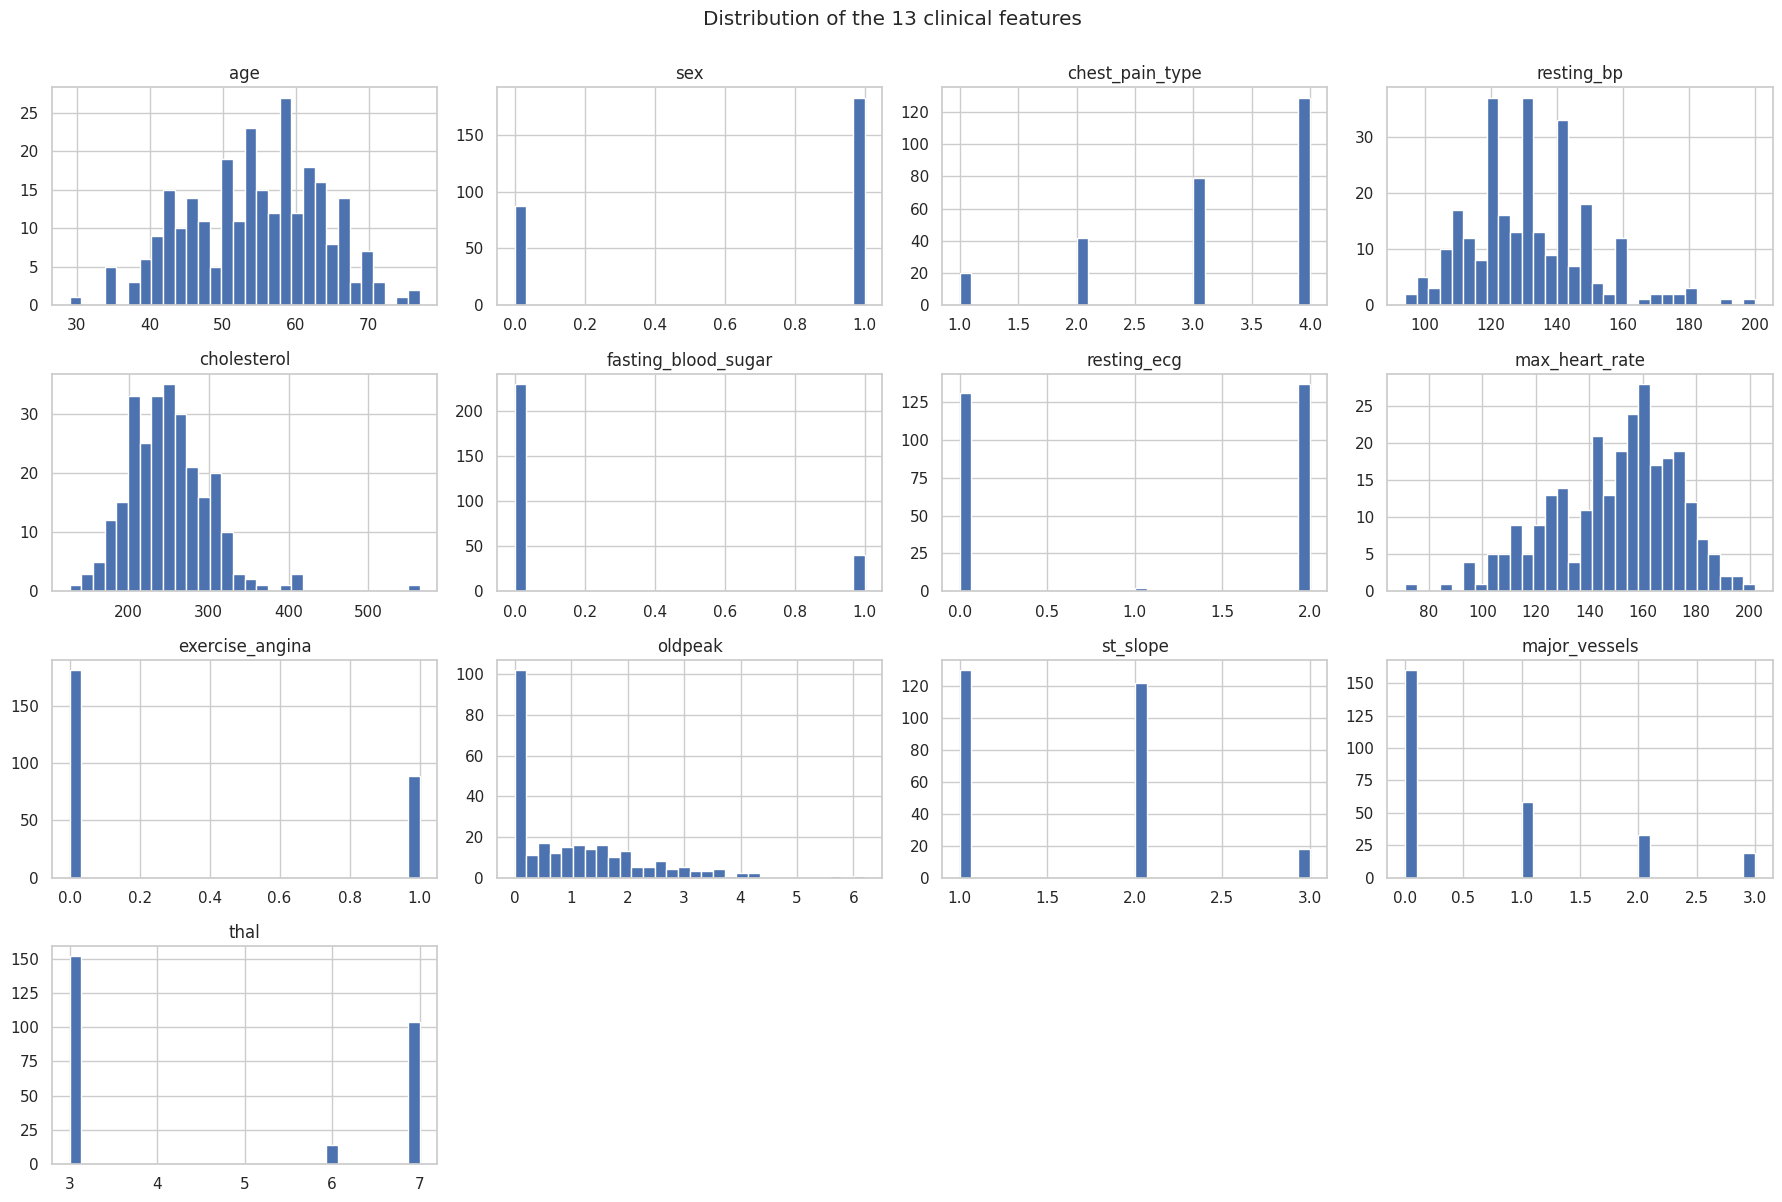

In [ ]:
df[FEATURES].hist(bins=30, figsize=(18, 12))
plt.suptitle("Distribution of the 13 clinical features", y=1.0)
plt.tight_layout()
save("histograms.png")
plt.show()

### Correlation heatmap

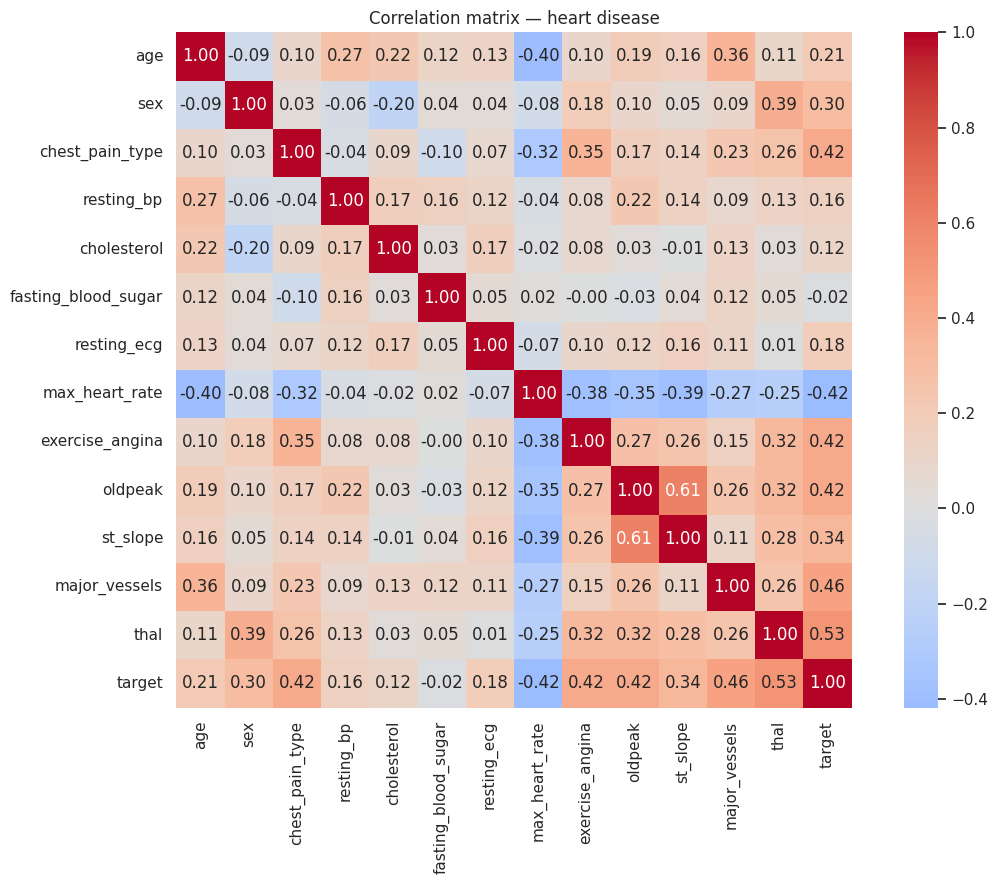

,target
thal,0.53
major_vessels,0.46
exercise_angina,0.42
max_heart_rate,-0.42
oldpeak,0.42
chest_pain_type,0.42
st_slope,0.34
sex,0.30
age,0.21
resting_ecg,0.18


In [ ]:
corr = df[FEATURES + ["target"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix — heart disease")
plt.tight_layout()
save("correlation_heatmap.png")
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2)

### Continuous variables — scatterplots

Pairs chosen from the heatmap and from clinical logic, coloured by diagnosis.

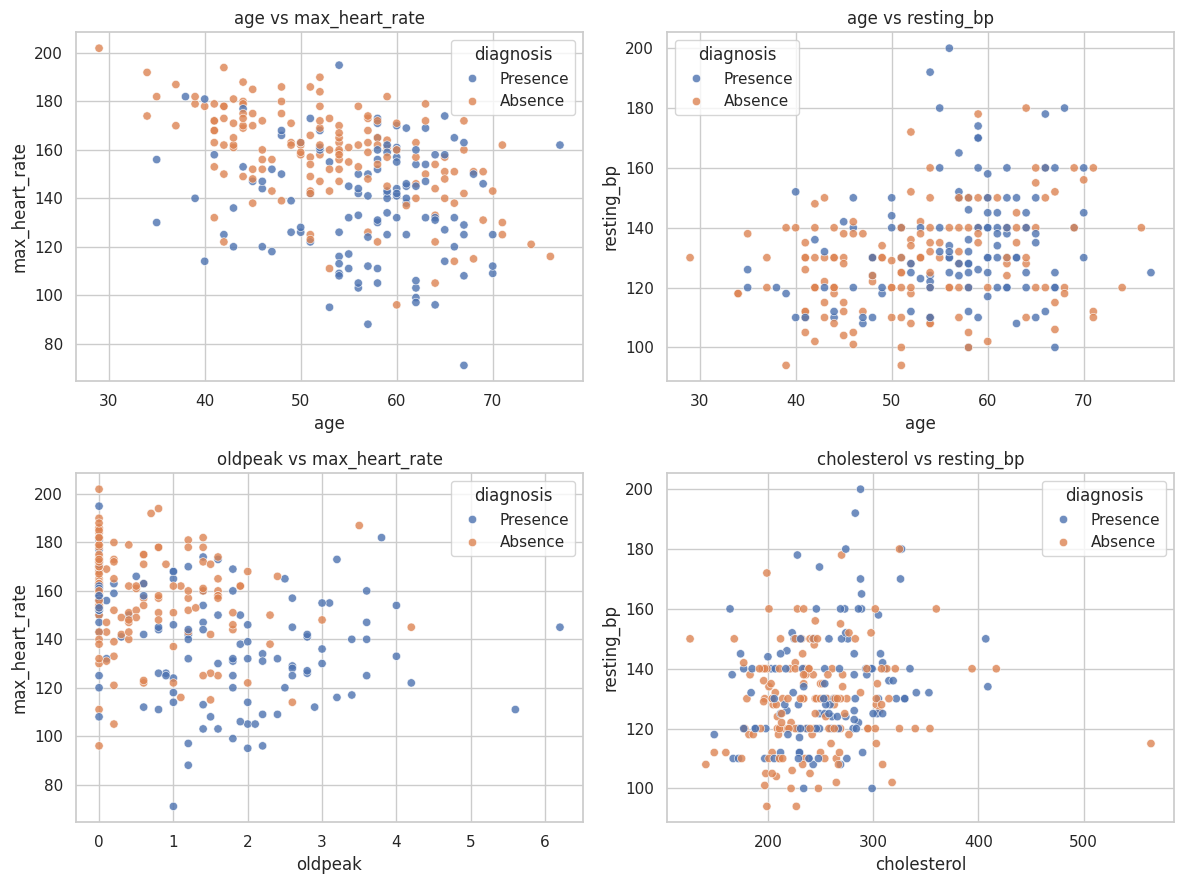

In [ ]:
pairs = [
    ("age", "max_heart_rate"),
    ("age", "resting_bp"),
    ("oldpeak", "max_heart_rate"),
    ("cholesterol", "resting_bp"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (x, y) in zip(axes.ravel(), pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="diagnosis", ax=ax, alpha=0.8)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
save("scatterplots.png")
plt.show()

### Categorical variables — boxplots

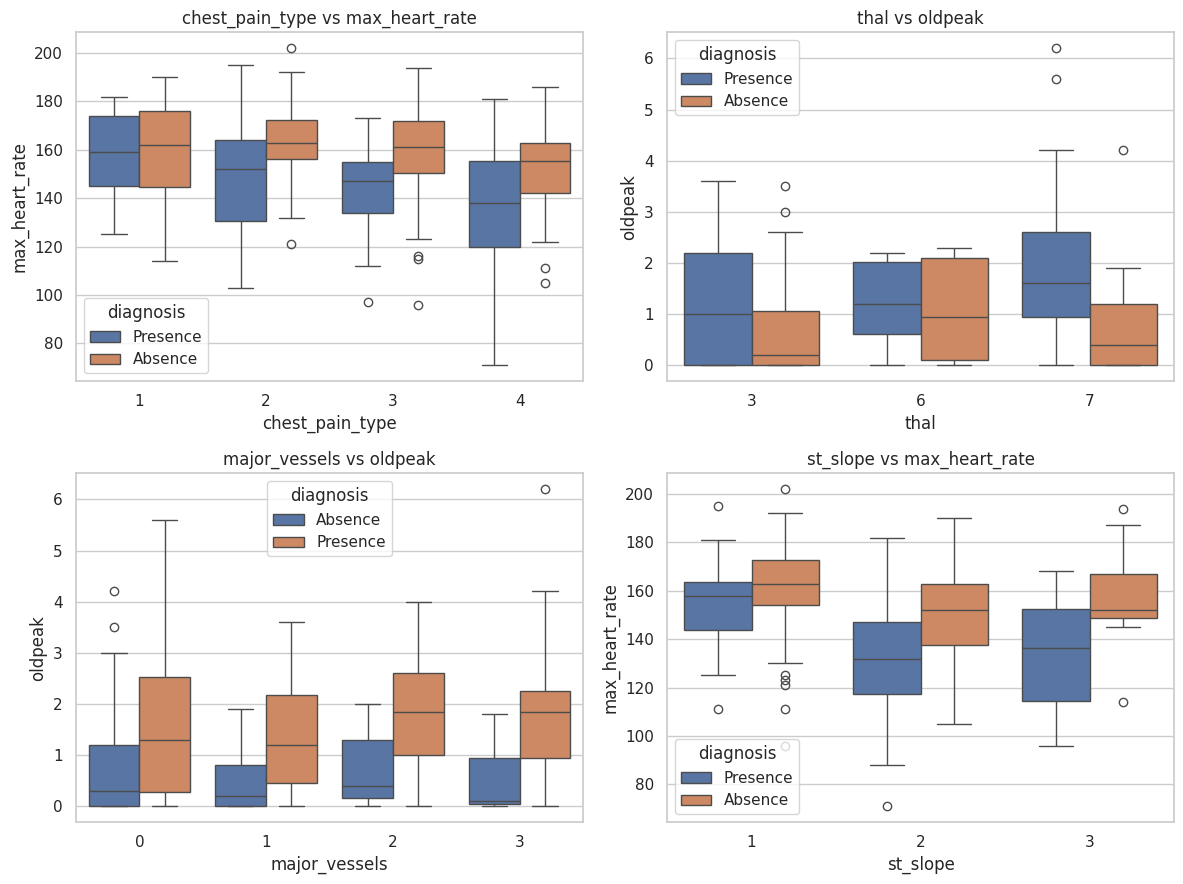

In [ ]:
box_pairs = [
    ("chest_pain_type", "max_heart_rate"),
    ("thal", "oldpeak"),
    ("major_vessels", "oldpeak"),
    ("st_slope", "max_heart_rate"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (x, y) in zip(axes.ravel(), box_pairs):
    sns.boxplot(data=df, x=x, y=y, hue="diagnosis", ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
save("boxplots.png")
plt.show()

## 3. Logistic Regression

Interpretable linear baseline. 80/20 train-test split (`random_state=42`), features standardised with a scaler fitted on the training set only.

In [ ]:
X = df[FEATURES]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=SEED, solver="lbfgs")
logreg.fit(X_train_s, y_train)
y_pred = logreg.predict(X_test_s)

print(f"Accuracy (train): {accuracy_score(y_train, logreg.predict(X_train_s)):.3f}")
print(f"Accuracy (test) : {accuracy_score(y_test, y_pred):.3f}")
print(f"Recall disease  : {recall_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Absence", "Presence"]))

Train: (216, 13) | Test: (54, 13)
Accuracy (train): 0.838
Accuracy (test) : 0.907
Recall disease  : 0.857

              precision    recall  f1-score   support

     Absence       0.91      0.94      0.93        33
    Presence       0.90      0.86      0.88        21

    accuracy                           0.91        54
   macro avg       0.91      0.90      0.90        54
weighted avg       0.91      0.91      0.91        54



**Reading the train/test gap.** Test accuracy is slightly *higher* than train accuracy. This does not prove the model is good: on 54 test patients, one partition can simply be easier than average. It does show there is no sign of overfitting. Cross-validation below gives a more reliable estimate.

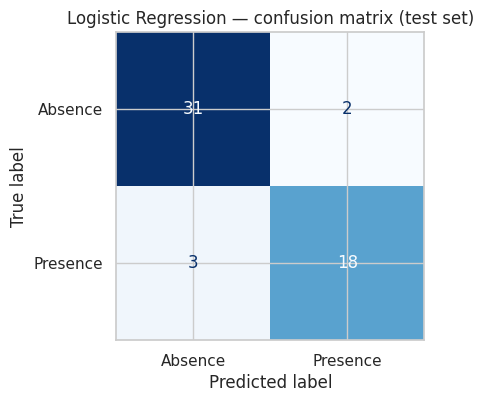

False negatives (sick patients missed): 3 / 21
False positives (healthy patients flagged): 2 / 33


In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Absence", "Presence"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Logistic Regression — confusion matrix (test set)")
save("confusion_matrix_logreg.png")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"False negatives (sick patients missed): {fn} / {fn + tp}")
print(f"False positives (healthy patients flagged): {fp} / {fp + tn}")

### Interpretability — which features drive the prediction?

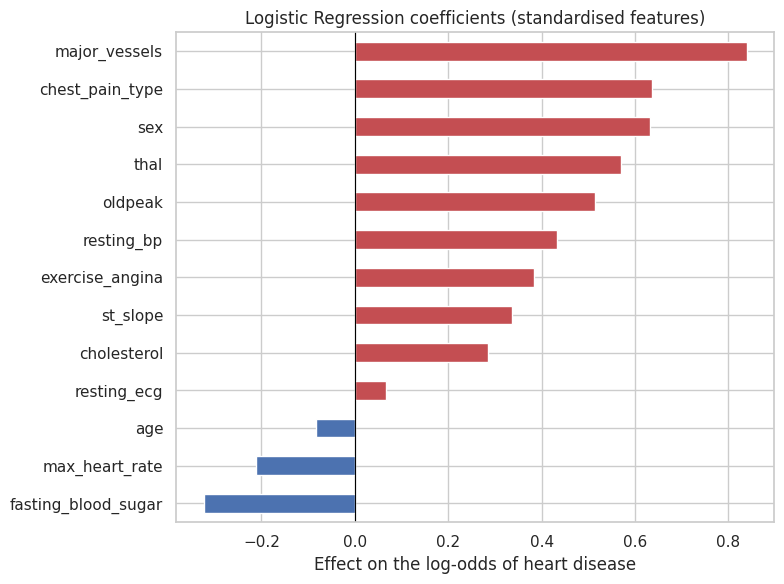

In [ ]:
coefs = pd.Series(logreg.coef_[0], index=FEATURES).sort_values()

plt.figure(figsize=(8, 6))
coefs.plot.barh(color=["#4C72B0" if v < 0 else "#C44E52" for v in coefs])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression coefficients (standardised features)")
plt.xlabel("Effect on the log-odds of heart disease")
plt.tight_layout()
save("logreg_coefficients.png")
plt.show()

### Stability check — 5-fold stratified cross-validation

A single 80/20 split on 270 patients is sensitive to which patients land in the test set. Cross-validation repeats the evaluation on 5 different partitions.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
scores = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "recall", "precision", "f1"])

cv_summary = pd.DataFrame({
    m: [scores[f"test_{m}"].mean(), scores[f"test_{m}"].std()]
    for m in ["accuracy", "recall", "precision", "f1"]
}, index=["mean", "std"]).round(3)
cv_summary

,accuracy,recall,precision,f1
mean,0.837,0.792,0.831,0.809
std,0.049,0.102,0.028,0.067


### Lowering the decision threshold to catch more sick patients

By default a patient is classified as sick when P(disease) ≥ 0.5. In a prevention setting, lowering the threshold trades a few extra false alarms for fewer missed patients.

In [ ]:
proba = logreg.predict_proba(X_test_s)[:, 1]
rows = []
for t in [0.5, 0.4, 0.3]:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    rows.append({"threshold": t, "recall": recall_score(y_test, pred_t),
                 "precision": precision_score(y_test, pred_t),
                 "false_negatives": fn, "false_positives": fp})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,false_negatives,false_positives
0,0.5,0.857,0.900,3,2
1,0.4,0.857,0.857,3,3
2,0.3,0.905,0.792,2,5


## 4. Artificial Neural Network

Architecture: 2 hidden layers of 20 ReLU neurons, sigmoid output, Adam optimiser, binary cross-entropy, 50 epochs, batch size 16.

Trained twice, on the **same split** as the Logistic Regression:
- on all 13 features;
- on the 5 continuous features only, to measure what the categorical features (thal, chest pain type, major vessels…) contribute.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense

tf.keras.utils.set_random_seed(SEED)

def train_ann(features):
    sc = StandardScaler()
    Xtr = sc.fit_transform(X_train[features])
    Xte = sc.transform(X_test[features])
    model = Sequential([
        Input(shape=(len(features),)),
        Dense(20, activation="relu"),
        Dense(20, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    model.fit(Xtr, y_train, epochs=50, batch_size=16, verbose=0)
    pred = (model.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)
    return pred

ann_all_pred = train_ann(FEATURES)
ann_cont_pred = train_ann(CONTINUOUS)

for name, pred in [("ANN — all 13 features", ann_all_pred), ("ANN — 5 continuous features", ann_cont_pred)]:
    print(f"{name}: accuracy {accuracy_score(y_test, pred):.3f} | recall disease {recall_score(y_test, pred):.3f}")

ANN — all 13 features: accuracy 0.833 | recall disease 0.714
ANN — 5 continuous features: accuracy 0.667 | recall disease 0.476


## 5. K-Means clustering (unsupervised)

Does the data contain natural patient groups, independently of the diagnosis? Features are standardised first, because K-Means is distance-based. The diagnosis is **not** used to build the clusters, only to describe them afterwards.

In [ ]:
X_all_s = StandardScaler().fit_transform(df[FEATURES])
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
clusters = kmeans.fit_predict(X_all_s)

print(pd.Series(clusters).value_counts().sort_index().rename("patients per cluster"))
pd.crosstab(clusters, df["diagnosis"], rownames=["cluster"], normalize="index").round(2)

0     67
1     93
2    110
Name: patients per cluster, dtype: int64


diagnosis,Absence,Presence
cluster,,
0,0.88,0.12
1,0.11,0.89
2,0.74,0.26


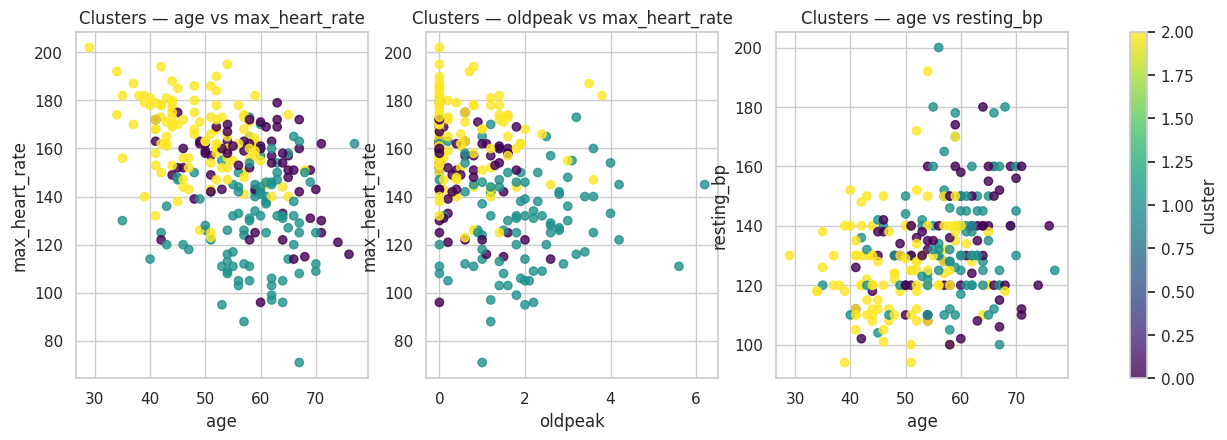

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x, y) in zip(axes, [("age", "max_heart_rate"), ("oldpeak", "max_heart_rate"), ("age", "resting_bp")]):
    sc = ax.scatter(df[x], df[y], c=clusters, cmap="viridis", alpha=0.8)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f"Clusters — {x} vs {y}")
fig.colorbar(sc, ax=axes, label="cluster")
save("kmeans_clusters.png")
plt.show()

K-Means on mixed data (continuous + categorical) is a methodological limit: categorical codes carry no real distance. K-Prototypes or a PCA projection would be better suited in a next iteration.

## 6. Model comparison

In [ ]:
results = pd.DataFrame([
    {"model": "Logistic Regression", "features": "all 13",
     "accuracy": accuracy_score(y_test, y_pred), "recall_disease": recall_score(y_test, y_pred),
     "f1_disease": f1_score(y_test, y_pred)},
    {"model": "ANN", "features": "all 13",
     "accuracy": accuracy_score(y_test, ann_all_pred), "recall_disease": recall_score(y_test, ann_all_pred),
     "f1_disease": f1_score(y_test, ann_all_pred)},
    {"model": "ANN", "features": "5 continuous",
     "accuracy": accuracy_score(y_test, ann_cont_pred), "recall_disease": recall_score(y_test, ann_cont_pred),
     "f1_disease": f1_score(y_test, ann_cont_pred)},
]).round(3)
results

,model,features,accuracy,recall_disease,f1_disease
0,Logistic Regression,all 13,0.907,0.857,0.878
1,ANN,all 13,0.833,0.714,0.769
2,ANN,5 continuous,0.667,0.476,0.526


## 7. Conclusions and limitations

**Findings**
- Logistic Regression is the best fit for this dataset: highest accuracy, good recall on the disease class, and fully interpretable coefficients a clinician can audit.
- The ANN does not beat it: 270 patients is too few to exploit non-linear interactions.
- Removing the categorical features sharply degrades the ANN: thal, major vessels and chest pain type carry much of the predictive signal.
- K-Means does not produce clean patient groups: cardiovascular risk appears as a continuum rather than as distinct archetypes.
- Asymptomatic chest pain (type 4) is associated with lower max heart rate — the silent profile that a screening model is best placed to flag.

**Limitations**
- Small dataset (270 patients): results depend on the split; cross-validation partly addresses this.
- About two thirds of the patients are men: performance may be lower for women. Any clinical use would require validation on a balanced, recent population.
- Old, single-source dataset: limited generalisability.
- Simple ANN: no dropout or early stopping.

**Next steps:** threshold tuning for recall, class weighting, ensemble methods, validation on an external dataset.

In [ ]:
!zip -r figures.zip figures
from google.colab import files
files.download("figures.zip")

  adding: figures/ (stored 0%)
  adding: figures/histograms.png (deflated 24%)
  adding: figures/correlation_heatmap.png (deflated 6%)
  adding: figures/kmeans_clusters.png (deflated 2%)
  adding: figures/boxplots.png (deflated 18%)
  adding: figures/logreg_coefficients.png (deflated 20%)
  adding: figures/confusion_matrix_logreg.png (deflated 17%)
  adding: figures/scatterplots.png (deflated 4%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>